<a href="https://colab.research.google.com/github/asema405/Maachine_Learning/blob/main/ML_PR4_B.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Все библиотеки успешно импортированы!")

Все библиотеки успешно импортированы!


In [2]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/tips.csv"

df = pd.read_csv(url)

print("Размер датасета:", df.shape)
display(df.head())

Размер датасета: (244, 7)


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [3]:
target = "tip"

numeric_features = ["total_bill", "size"]

X = df[numeric_features].copy()
y = df[target].copy()

print("Признаки модели:", numeric_features)
print("Целевая переменная:", target)
print("Размер X:", X.shape)
print("Размер y:", y.shape)

Признаки модели: ['total_bill', 'size']
Целевая переменная: tip
Размер X: (244, 2)
Размер y: (244,)


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Размер обучающей выборки:", X_train.shape)
print("Размер тестовой выборки:", X_test.shape)

Размер обучающей выборки: (195, 2)
Размер тестовой выборки: (49, 2)


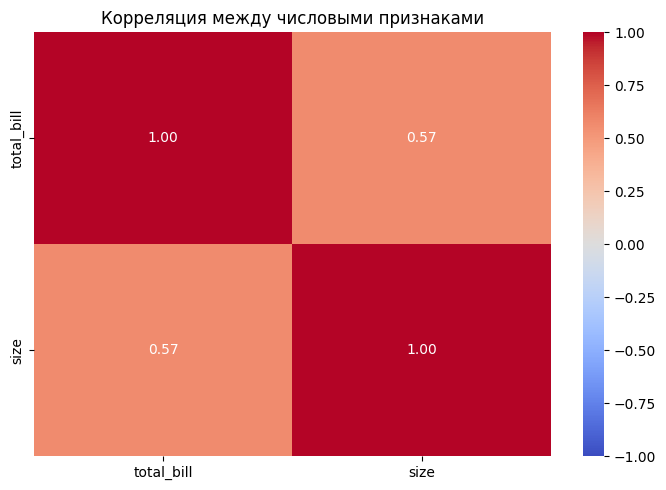

In [5]:
corr_matrix = X_train.corr()

plt.figure(figsize=(7, 5))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Корреляция между числовыми признаками")
plt.tight_layout()
plt.show()

In [6]:
baseline_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]
)

baseline_pipeline.fit(X_train, y_train)

print("Базовая модель успешно обучена!")

Базовая модель успешно обучена!


In [7]:
y_pred_baseline = baseline_pipeline.predict(X_test)

mae_baseline = mean_absolute_error(y_test, y_pred_baseline)
mse_baseline = mean_squared_error(y_test, y_pred_baseline)
rmse_baseline = np.sqrt(mse_baseline)
r2_baseline = r2_score(y_test, y_pred_baseline)

print("БАЗОВАЯ МОДЕЛЬ")
print(f"MAE:  {mae_baseline:.3f}")
print(f"RMSE: {rmse_baseline:.3f}")
print(f"R²:   {r2_baseline:.3f}")

БАЗОВАЯ МОДЕЛЬ
MAE:  0.664
RMSE: 0.805
R²:   0.481


In [8]:
X_reduced = df[["total_bill"]].copy()

X_train_red, X_test_red, y_train_red, y_test_red = train_test_split(
    X_reduced,
    y,
    test_size=0.2,
    random_state=42
)

reduced_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]
)

reduced_pipeline.fit(X_train_red, y_train_red)

y_pred_reduced = reduced_pipeline.predict(X_test_red)

print("Сокращённая модель обучена!")

Сокращённая модель обучена!


In [9]:
results = pd.DataFrame({
    "Модель": [
        "Базовая: total_bill + size",
        "Сокращённая: total_bill"
    ],
    "MAE": [
        mean_absolute_error(y_test, y_pred_baseline),
        mean_absolute_error(y_test_red, y_pred_reduced)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, y_pred_baseline)),
        np.sqrt(mean_squared_error(y_test_red, y_pred_reduced))
    ],
    "R2": [
        r2_score(y_test, y_pred_baseline),
        r2_score(y_test_red, y_pred_reduced)
    ]
})

display(results.round(3))

,Модель,MAE,RMSE,R2
0,Базовая: total_bill + size,0.664,0.805,0.481
1,Сокращённая: total_bill,0.621,0.754,0.545


In [10]:
baseline_model = baseline_pipeline.named_steps["model"]

coef_table = pd.DataFrame({
    "Признак": numeric_features,
    "Коэффициент": baseline_model.coef_
})

display(coef_table.round(3))

print("Свободный член (intercept):", round(baseline_model.intercept_, 3))

,Признак,Коэффициент
0,total_bill,0.795
1,size,0.249


Свободный член (intercept): 3.088


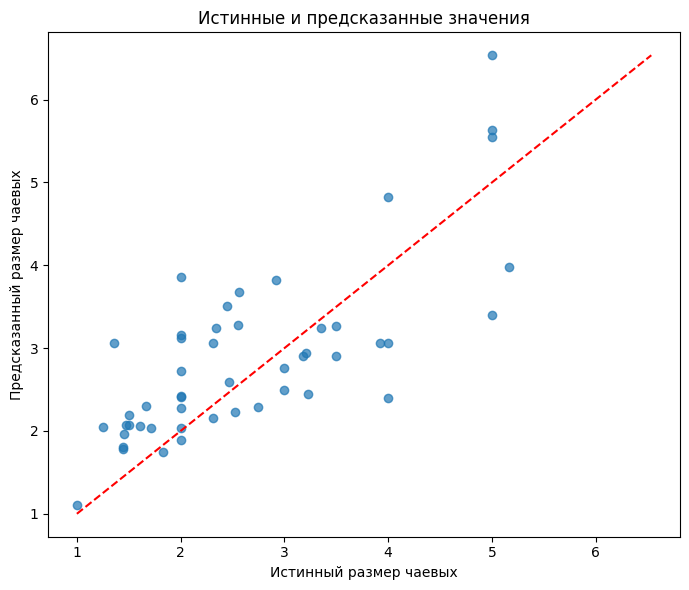

In [11]:
plt.figure(figsize=(7, 6))

plt.scatter(y_test, y_pred_baseline, alpha=0.7)

low = min(y_test.min(), y_pred_baseline.min())
high = max(y_test.max(), y_pred_baseline.max())

plt.plot([low, high], [low, high], "r--")

plt.xlabel("Истинный размер чаевых")
plt.ylabel("Предсказанный размер чаевых")
plt.title("Истинные и предсказанные значения")
plt.tight_layout()
plt.show()

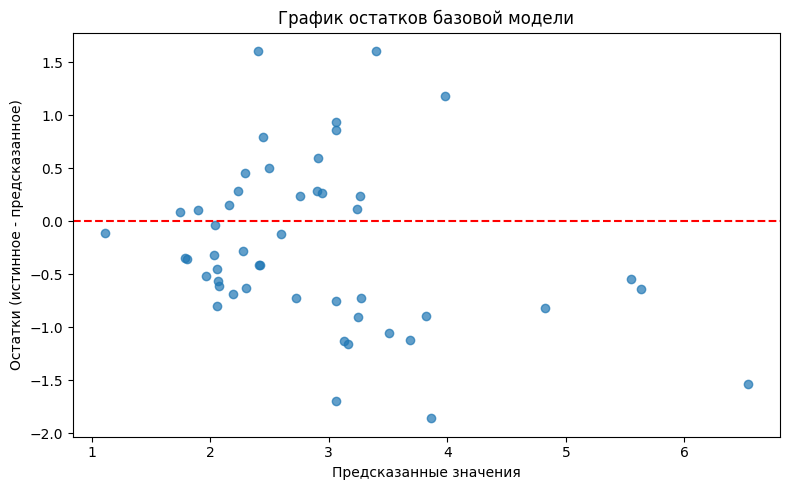

In [12]:
residuals = y_test - y_pred_baseline

plt.figure(figsize=(8, 5))

plt.scatter(y_pred_baseline, residuals, alpha=0.7)
plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Предсказанные значения")
plt.ylabel("Остатки (истинное - предсказанное)")
plt.title("График остатков базовой модели")
plt.tight_layout()
plt.show()

In [13]:
best_index = results["RMSE"].idxmin()
best_model_name = results.loc[best_index, "Модель"]

print("Финальная модель по минимальному RMSE:")
print(best_model_name)

print("\nСравнение метрик:")
display(results.round(3))

Финальная модель по минимальному RMSE:
Сокращённая: total_bill

Сравнение метрик:


,Модель,MAE,RMSE,R2
0,Базовая: total_bill + size,0.664,0.805,0.481
1,Сокращённая: total_bill,0.621,0.754,0.545


## Итоговый отчёт по практической работе № 4

### 1. Цель работы

Построить модель линейной регрессии для прогнозирования размера чаевых (`tip`) на основе числовых признаков ресторанного датасета `tips`.

### 2. Подготовка данных

В качестве целевой переменной выбран признак `tip`. Для базовой модели использованы признаки `total_bill` и `size`. Данные разделены на обучающую и тестовую выборки в соотношении 80/20.

### 3. Предобработка

Для заполнения возможных пропусков применена медиана, а для масштабирования признаков — `StandardScaler`. Оба преобразования включены в `Pipeline` и обучаются только на тренировочной выборке, что предотвращает утечку информации из тестовых данных.

### 4. Проверка мультиколлинеарности

Для оценки связи между числовыми признаками построена корреляционная матрица. По её результатам рассмотрена возможность исключения признака `size` и сравнения качества моделей на полном и сокращённом наборах признаков.

### 5. Сравнение моделей

Базовая модель использует `total_bill` и `size`, а сокращённая — только `total_bill`. Качество моделей сравнивается по MAE, RMSE и R² на тестовой выборке. Финальная модель выбирается с учётом ошибки прогнозирования и простоты интерпретации.

### 6. Анализ остатков

Построен график остатков базовой модели. По расположению точек относительно нулевой линии оценивается наличие систематического паттерна и возможных нарушений допущений линейной регрессии.

### 7. Вывод

В ходе работы построены и сравнены две модели линейной регрессии. Метрики на тестовой выборке позволяют оценить точность прогнозирования чаевых. Финальный выбор признаков должен основываться на фактических результатах сравнения моделей, а не только на количестве используемых признаков.

In [ ]:
from pathlib import Path

Path("data").mkdir(exist_ok=True)
Path("notebooks").mkdir(exist_ok=True)

df.to_csv("data/tips.csv", index=False)

readme = """# Практическая работа № 4. Регрессионная модель

ФИО: Ашимова Асема Дамировна

Вариант: B

Датасет: Tips — данные о счетах и чаевых в ресторане.

Среда выполнения: Google Colab.

Целевая переменная: tip.

Выполненные задания:
- Обучение базовой модели линейной регрессии.
- Проверка корреляции между признаками.
- Обучение сокращённой модели.
- Сравнение MAE, RMSE и R².
- Построение графика предсказаний.
- Анализ графика остатков.
- Выбор финальной модели по результатам сравнения.
"""

Path("README.md").write_text(readme, encoding="utf-8")

print("README.md и data/tips.csv сохранены.")